# 4. Predict popularity among known hits

Filter the saved training and holdout partitions separately to popularity > 70. Never train on a hit from the shared holdout. Compare the same eight regressors with a high-popularity training-mean baseline.

In [1]:
from pipeline_lib import RunContext, train_models
ctx = RunContext.from_environment("regression_high")
print("Profile:", ctx.config["profile"])
print("Artifacts:", ctx.run_dir)
from IPython.display import Image, display
train, holdout = ctx.data()
print('High-popularity training rows:', (train.popularity > ctx.config['hit_threshold']).sum())
print('High-popularity holdout rows:', (holdout.popularity > ctx.config['hit_threshold']).sum())

Profile: smoke
Artifacts: /Users/anishech/Projects/ML_Spotify/runs/20261021_135938_718078_smoke
High-popularity training rows: 203
High-popularity holdout rows: 51


The popularity range is narrow, so a small absolute error or high ±5 percentage may still have weak R². This model estimates scores conditional on being a hit. The combined stage will also encounter classifier false positives, which this model has not been trained to represent.

In [2]:
high_results = train_models(ctx, high_only=True)
display(high_results)

START Lasso: 2 candidates x 2 folds + refit; train=203 holdout=51


Fitting 2 folds for each of 2 candidates, totalling 4 fits


DONE Lasso: CV neg_rmse=-4.6038; holdout {'rows': 51, 'mae': 2.9480622106532626, 'rmse': 3.7556102641745484, 'r2': 0.15687427387785557, 'within_5_percent': 86.27450980392157}; 0.9s


START Ridge: 2 candidates x 2 folds + refit; train=203 holdout=51


DONE Ridge: CV neg_rmse=-4.6647; holdout {'rows': 51, 'mae': 2.8706304749507034, 'rmse': 3.7447771038202027, 'r2': 0.16173129700940048, 'within_5_percent': 84.31372549019608}; 0.0s


...

Fitting 2 folds for each of 2 candidates, totalling 4 fits
[CV] END model__learning_rate=0.2, model__max_depth=4, model__max_features=log2, model__min_samples_leaf=1, model__min_samples_split=10, model__n_estimators=30, model__subsample=1.0; total time=   0.0s
[CV] END model__learning_rate=0.2, model__max_depth=4, model__max_features=log2, model__min_samples_leaf=1, model__min_samples_split=10, model__n_estimators=30, model__subsample=1.0; total time=   0.0s
[CV] END model__learning_rate=0.005, model__max_depth=4, model__max_features=None, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=30, model__subsample=0.6; total time=   0.0s
[CV] END model__learning_rate=0.005, model__max_depth=4, model__max_features=None, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=30, model__subsample=0.6; total time=   0.0s
Fitting 2 folds for each of 2 candidates, totalling 4 fits
[CV] END model__learning_rate=0.1, model__loss=linear, model__n_estima

DONE XGBRegressor: CV neg_rmse=-4.6410; holdout {'rows': 51, 'mae': 3.2047550678253174, 'rmse': 4.000949270142757, 'r2': 0.04312020540237427, 'within_5_percent': 86.27450980392157}; 0.1s


Selected ElasticNet using neg_rmse from training folds only


[CV] END model__colsample_bytree=0.7, model__gamma=0.3, model__learning_rate=0.005, model__max_depth=3, model__n_estimators=50, model__reg_alpha=0.1, model__reg_lambda=2.5, model__subsample=0.6; total time=   0.0s
[CV] END model__colsample_bytree=0.7, model__gamma=0.3, model__learning_rate=0.005, model__max_depth=3, model__n_estimators=50, model__reg_alpha=0.1, model__reg_lambda=2.5, model__subsample=0.6; total time=   0.0s
[CV] END model__colsample_bytree=0.6, model__gamma=0, model__learning_rate=0.01, model__max_depth=4, model__n_estimators=30, model__reg_alpha=1.0, model__reg_lambda=1, model__subsample=0.6; total time=   0.0s
[CV] END model__colsample_bytree=0.6, model__gamma=0, model__learning_rate=0.01, model__max_depth=4, model__n_estimators=30, model__reg_alpha=1.0, model__reg_lambda=1, model__subsample=0.6; total time=   0.0s


,model,cv_selection_score,test_rows,test_mae,test_rmse,test_r2,test_within_5_percent,seconds,train_rows,train_mae,train_rmse,train_r2,train_within_5_percent
0,MeanBaseline,NaN,51,3.285907,4.092911,-0.001373,88.235294,NaN,NaN,NaN,NaN,NaN,NaN
1,Lasso,-4.603839,51,2.948062,3.755610,0.156874,86.274510,0.929632,203.0,3.160779,4.076029,0.268974,85.714286
2,Ridge,-4.664750,51,2.870630,3.744777,0.161731,84.313725,0.022141,203.0,3.027704,3.951281,0.313036,83.251232
3,ElasticNet,-4.578904,51,3.018291,3.791454,0.140704,84.313725,0.021827,203.0,3.261211,4.183284,0.229996,85.714286
4,RandomForestRegressor,-4.641876,51,3.129304,3.909057,0.086570,80.392157,0.136689,203.0,2.725032,3.572578,0.438407,88.669951
5,GradientBoostingRegressor,-4.663930,51,3.265047,4.053315,0.017908,84.313725,0.057928,203.0,3.537579,4.563667,0.083598,84.236453
6,AdaBoostRegressor,-4.634860,51,3.140367,3.887023,0.096838,82.352941,0.110249,203.0,3.009263,3.730134,0.387781,88.669951
7,KNeighborsRegressor,-4.647776,51,3.009873,3.939554,0.072262,82.352941,0.023729,203.0,1.914512,3.015151,0.599985,93.596059
8,XGBRegressor,-4.641040,51,3.204755,4.000949,0.043120,86.274510,0.052458,203.0,3.443477,4.444298,0.130910,86.206897


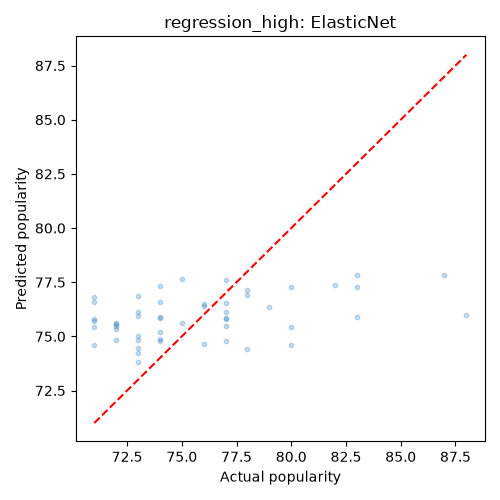

In [3]:
display(Image(filename=str(ctx.path('plots', 'regression_high_predictions.png'))))

The best complete high-popularity regression pipeline is saved under `models/regression_high_best.joblib`. Selection uses training cross-validation only.